# 02. Limpieza y preparación de características
La predicción se realiza **dos horas antes de la salida programada**. Enero–octubre se utiliza para explorar y preparar los datos; noviembre queda separado. Diciembre no se utiliza.

Se calculan la limpieza, el análisis exploratorio y los conjuntos de características A y B. No se entrena ningún clasificador en este notebook.


## 1. Datos y etiqueta
Se cargan vuelos, clima y catálogos. Las uniones conservan una fila por vuelo. La etiqueta es 1 si `arr_delay >= 15`; permanece desconocida cuando falta ese dato.


In [1]:
import sys
from pathlib import Path
sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
raiz = Path.cwd()
if not (raiz / 'src').exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz / 'src'))
sns.set_theme(style='whitegrid')
from data import load_raw, TARGET_COL, LEAKAGE_COLS
from features import FEATURES_A, FEATURES_B, EXTRA_CLIMA, CLIMA, HISTORICAS
pd.set_option('display.max_columns', 45)


C:\Users\Rodrigo D SantaMaria\AppData\Local\Programs\Python\Python313\Lib\site-packages\nycflights13\__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename as _rf


In [2]:
raw = load_raw()
vuelos = raw['flights']
vuelos = vuelos.loc[vuelos['month'].between(1, 11)].copy().reset_index(names='id_vuelo')
clima = raw['weather']
clima = clima.loc[clima['month'].between(1, 11)].copy()
vuelos['time_hour'] = pd.to_datetime(vuelos['time_hour'], utc=True)
clima['time_hour'] = pd.to_datetime(clima['time_hour'], utc=True)
aviones, aerolineas, aeropuertos = raw['planes'], raw['airlines'], raw['airports']
del raw


In [3]:
datos = vuelos.merge(
    aviones[['tailnum', 'year', 'manufacturer', 'model', 'engines', 'seats', 'engine']]
    .rename(columns={'year': 'plane_year'}),
    on='tailnum', how='left', validate='many_to_one'
)
datos = datos.merge(clima.drop(columns=['year', 'month', 'day', 'hour']),
                    on=['origin', 'time_hour'], how='left', validate='many_to_one')
datos = datos.merge(aerolineas, on='carrier', how='left', validate='many_to_one')
datos = datos.merge(
    aeropuertos[['faa', 'lat', 'lon', 'alt']].rename(columns={
        'faa': 'dest', 'lat': 'dest_lat', 'lon': 'dest_lon', 'alt': 'dest_alt'}),
    on='dest', how='left', validate='many_to_one'
)
datos[TARGET_COL] = (datos['arr_delay'] >= 15).astype('Int64')
datos.loc[datos['arr_delay'].isna(), TARGET_COL] = pd.NA


In [4]:
assert len(datos) == len(vuelos) and datos['id_vuelo'].is_unique
assert datos[TARGET_COL].isna().equals(datos['arr_delay'].isna())
print('Filas y columnas:', datos.shape)
display(datos.dtypes.value_counts().rename('columnas_por_tipo'))


Filas y columnas: (308641, 40)


float64                20
int64                  10
object                  8
datetime64[ns, UTC]     1
Int64                   1
Name: columnas_por_tipo, dtype: int64

Las uniones permiten revisar la calidad de los datos. El clima de la hora programada y los atributos de aeronaves **no se utilizan como predictores**. La coincidencia de una matrícula no garantiza que el catálogo describa la aeronave correcta.

## 2. Faltantes y registros sin etiqueta
La exploración utiliza enero–octubre. Se conservan los registros sin etiqueta y se describen por separado; una llegada no observada no demuestra una cancelación.


In [5]:
desarrollo = datos.loc[datos['month'] <= 10].copy()
eda = desarrollo.dropna(subset=[TARGET_COL]).copy()
eda[TARGET_COL] = eda[TARGET_COL].astype(int)
faltantes = pd.DataFrame({'cantidad': desarrollo.isna().sum(),
                         'porcentaje': 100 * desarrollo.isna().mean()})
faltantes = faltantes.sort_values('porcentaje', ascending=False)
display(faltantes.loc[faltantes['cantidad'] > 0].round(2))


,cantidad,porcentaje
wind_gust,213965,76.04
plane_year,48641,17.29
model,44188,15.70
manufacturer,44188,15.70
engine,44188,15.70
engines,44188,15.70
seats,44188,15.70
pressure,30424,10.81
wind_dir,8026,2.85
arr_delay,8018,2.85


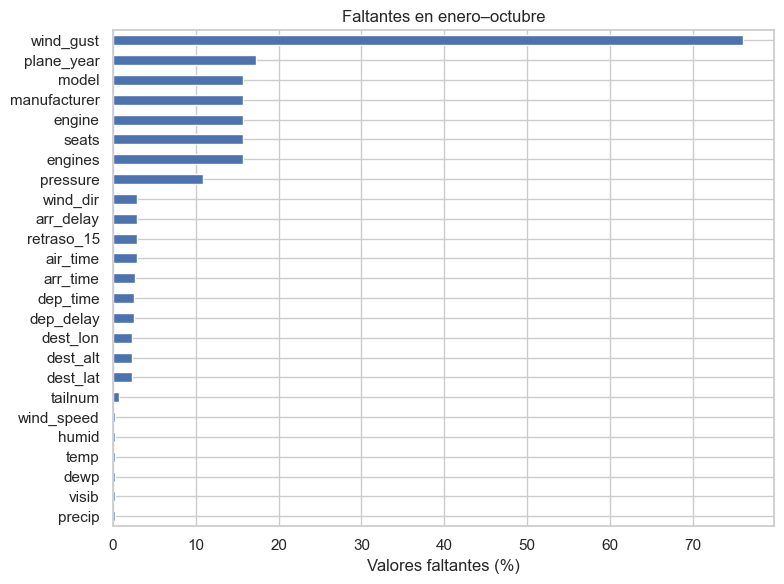

In [6]:
faltantes.loc[faltantes['cantidad'] > 0, 'porcentaje'].sort_values().plot.barh(figsize=(8, 6))
plt.xlabel('Valores faltantes (%)')
plt.title('Faltantes en enero–octubre')
plt.tight_layout()
plt.show()


In [7]:
sin_target = desarrollo.loc[desarrollo['arr_delay'].isna()].copy()
resumen_sin_target = pd.DataFrame({
    'situacion': ['Sin salida registrada', 'Con salida, sin llegada registrada', 'Con salida y llegada'],
    'vuelos': [sin_target['dep_time'].isna().sum(),
               (sin_target['dep_time'].notna() & sin_target['arr_time'].isna()).sum(),
               (sin_target['dep_time'].notna() & sin_target['arr_time'].notna()).sum()]
})
assert resumen_sin_target['vuelos'].sum() == len(sin_target)
display(resumen_sin_target)
print(f'Sin target: {len(sin_target):,} ({100 * len(sin_target) / len(desarrollo):.2f}%).')


,situacion,vuelos
0,Sin salida registrada,6997
1,"Con salida, sin llegada registrada",404
2,Con salida y llegada,617


Sin target: 8,018 (2.85%).


Los faltantes no tienen una causa única. Los vuelos sin `arr_delay` se excluyen del aprendizaje supervisado, sin convertir su etiqueta en 0.

## 3. Retrasos extremos
Se muestra la distribución entre −60 y 180 minutos para facilitar su lectura. Los valores externos se conservan en el dataset.


In [8]:
display(eda['arr_delay'].describe().to_frame('arr_delay'))
print('Retrasos superiores a 500 minutos:', eda['arr_delay'].gt(500).sum())


,arr_delay
count,273355.000000
mean,6.741907
std,45.471364
min,-86.000000
25%,-17.000000
50%,-5.000000
75%,13.000000
max,1272.000000


Retrasos superiores a 500 minutos: 42


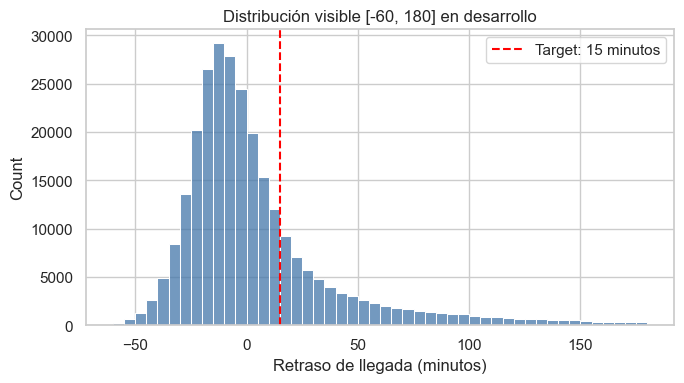

Observación: mediana -5 min; máximo 1272 min.
Fuera del gráfico quedan 3,563 vuelos; no se borran.


In [9]:
visibles = eda.loc[eda['arr_delay'].between(-60, 180), 'arr_delay']
plt.figure(figsize=(7, 4))
sns.histplot(visibles, bins=48, color='#4477AA')
plt.axvline(15, color='red', linestyle='--', label='Target: 15 minutos')
plt.xlabel('Retraso de llegada (minutos)')
plt.title('Distribución visible [-60, 180] en desarrollo')
plt.legend()
plt.tight_layout()
plt.show()
print(f'Observación: mediana {eda["arr_delay"].median():.0f} min; máximo {eda["arr_delay"].max():.0f} min.')
print(f'Fuera del gráfico quedan {len(eda) - len(visibles):,} vuelos; no se borran.')


Los extremos pueden corresponder a vuelos reales. El recorte afecta únicamente a la visualización y no constituye una regla de eliminación.

## 4. Retrasos por aeropuerto, día, ruta y horario
Se comparan cantidades y porcentajes. Las rutas requieren al menos 1.000 vuelos etiquetados en desarrollo. Las diferencias son asociaciones, no efectos causales.


,vuelos,porcentaje
origin,,
EWR,98114,26.07
JFK,91511,23.57
LGA,83730,22.69


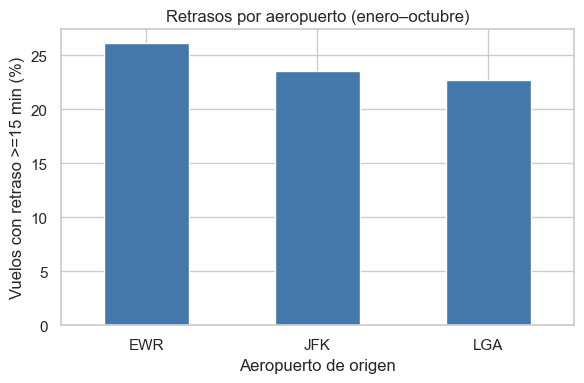

Observación: EWR presenta la mayor tasa (26.07%). Esto no demuestra un efecto causal del aeropuerto.


In [10]:
por_aeropuerto = eda.groupby('origin')[TARGET_COL].agg(vuelos='size', tasa='mean')
por_aeropuerto['porcentaje'] = 100 * por_aeropuerto['tasa']
display(por_aeropuerto[['vuelos', 'porcentaje']].round(2))
por_aeropuerto['porcentaje'].plot.bar(color='#4477AA', rot=0, figsize=(6, 4))
plt.ylabel('Vuelos con retraso >=15 min (%)')
plt.xlabel('Aeropuerto de origen')
plt.title('Retrasos por aeropuerto (enero–octubre)')
plt.tight_layout()
plt.show()
print(f'Observación: {por_aeropuerto["porcentaje"].idxmax()} presenta la mayor tasa '
      f'({por_aeropuerto["porcentaje"].max():.2f}%). Esto no demuestra un efecto causal del aeropuerto.')


In [11]:
eda['dia_semana'] = pd.to_datetime(eda[['year', 'month', 'day']]).dt.dayofweek
nombres_dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
por_dia = eda.groupby('dia_semana')[TARGET_COL].agg(vuelos='size', tasa='mean').reindex(range(7))
por_dia['porcentaje'] = 100 * por_dia['tasa']
por_dia['dia'] = nombres_dias
display(por_dia[['dia', 'vuelos', 'porcentaje']].round(2))


,dia,vuelos,porcentaje
dia_semana,,,
0,Lunes,40688,25.87
1,Martes,41213,22.28
2,Miércoles,41189,24.80
3,Jueves,41207,29.11
4,Viernes,40193,27.58
5,Sábado,31258,17.05
6,Domingo,37607,20.79


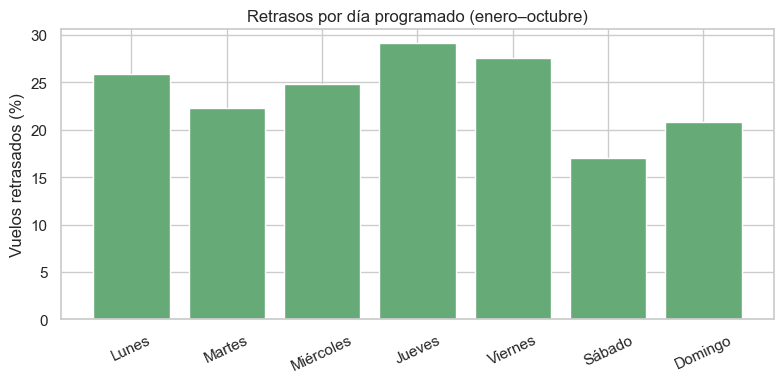

Observación: mayor tasa en Jueves (29.11%); menor en Sábado (17.05%).
No atribuimos la diferencia al día por sí solo: también cambia la composición de vuelos.


In [12]:
plt.figure(figsize=(8, 4))
plt.bar(por_dia['dia'], por_dia['porcentaje'], color='#66AA77')
plt.ylabel('Vuelos retrasados (%)')
plt.title('Retrasos por día programado (enero–octubre)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()
print(f'Observación: mayor tasa en {por_dia.loc[por_dia["porcentaje"].idxmax(), "dia"]} '
      f'({por_dia["porcentaje"].max():.2f}%); menor en '
      f'{por_dia.loc[por_dia["porcentaje"].idxmin(), "dia"]} ({por_dia["porcentaje"].min():.2f}%).')
print('No atribuimos la diferencia al día por sí solo: también cambia la composición de vuelos.')


In [13]:
MIN_VUELOS_RUTA = 1000
por_ruta = eda.groupby(['origin', 'dest'])[TARGET_COL].agg(vuelos='size', tasa='mean')
rutas_suficientes = por_ruta.loc[por_ruta['vuelos'] >= MIN_VUELOS_RUTA].copy()
rutas_suficientes['porcentaje'] = 100 * rutas_suficientes['tasa']
top_rutas = rutas_suficientes.sort_values('porcentaje', ascending=False).head(10)
display(top_rutas[['vuelos', 'porcentaje']].round(2))


vuelos  porcentaje
origin dest                    
EWR    RIC     1343       40.95
       DCA     1398       40.49
       MCI     1073       37.56
       CHS     1124       32.30
       STL     1996       31.66
JFK    PBI     1427       31.53
       ORD     1881       30.62
       AUS     1215       30.12
EWR    CVG     2124       29.94
       IAD     1018       29.27

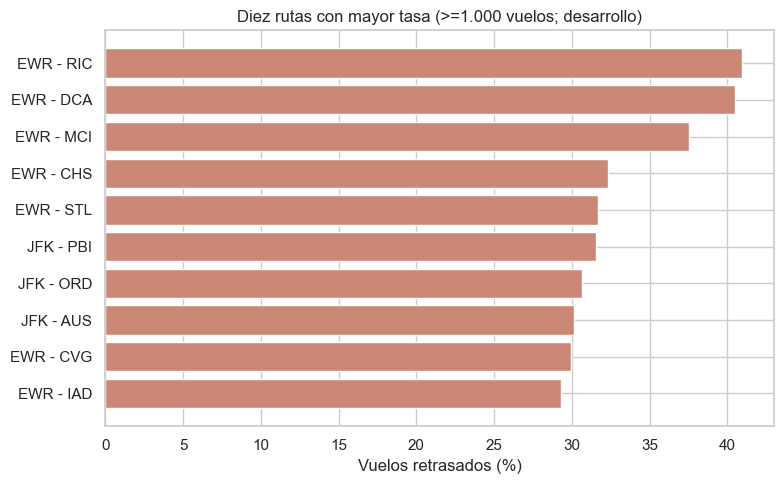

Observación: EWR–RIC encabeza las elegibles con 40.95% y 1,343 vuelos.
Cumplen el mínimo 85 de 220 rutas. No es un ranking de todas las rutas.


In [14]:
etiquetas = [origen + ' - ' + destino for origen, destino in top_rutas.index]
plt.figure(figsize=(8, 5))
plt.barh(etiquetas[::-1], top_rutas['porcentaje'].iloc[::-1], color='#CC8877')
plt.xlabel('Vuelos retrasados (%)')
plt.title('Diez rutas con mayor tasa (>=1.000 vuelos; desarrollo)')
plt.tight_layout()
plt.show()
ruta = top_rutas.index[0]
print(f'Observación: {ruta[0]}–{ruta[1]} encabeza las elegibles con '
      f'{top_rutas.iloc[0]["porcentaje"]:.2f}% y {int(top_rutas.iloc[0]["vuelos"]):,} vuelos.')
print(f'Cumplen el mínimo {len(rutas_suficientes)} de {len(por_ruta)} rutas. No es un ranking de todas las rutas.')


In [15]:
por_hora = eda.groupby('hour')[TARGET_COL].agg(vuelos='size', tasa='mean')
por_hora['porcentaje'] = 100 * por_hora['tasa']
display(por_hora[['vuelos', 'porcentaje']].round(2))


,vuelos,porcentaje
hour,,
5,1629,10.19
6,21556,11.38
7,18649,11.29
8,22321,15.54
9,16567,16.29
10,13556,17.72
11,13214,17.99
12,14775,20.22
13,16179,23.50


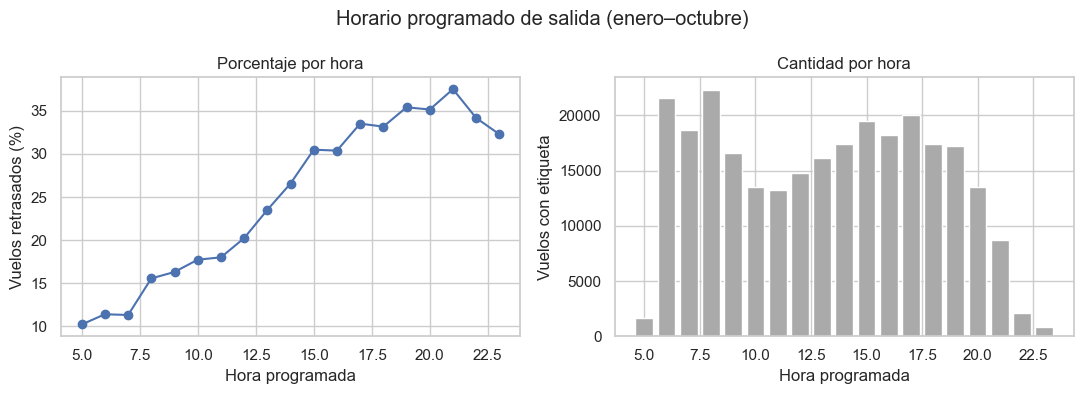

Observación: a las 6 h la tasa es 11.38% y a las 20 h es 35.16%.
Las horas con pocos vuelos requieren cautela; el panel derecho muestra sus tamaños de muestra.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(por_hora.index, por_hora['porcentaje'], marker='o')
axes[0].set(xlabel='Hora programada', ylabel='Vuelos retrasados (%)', title='Porcentaje por hora')
axes[1].bar(por_hora.index, por_hora['vuelos'], color='#AAAAAA')
axes[1].set(xlabel='Hora programada', ylabel='Vuelos con etiqueta', title='Cantidad por hora')
plt.suptitle('Horario programado de salida (enero–octubre)')
plt.tight_layout()
plt.show()
print(f'Observación: a las 6 h la tasa es {por_hora.loc[6, "porcentaje"]:.2f}% '
      f'y a las 20 h es {por_hora.loc[20, "porcentaje"]:.2f}%.')
print('Las horas con pocos vuelos requieren cautela; el panel derecho muestra sus tamaños de muestra.')


EWR presenta la mayor tasa entre los tres aeropuertos; jueves supera a sábado y EWR–RIC encabeza las rutas elegibles. Las cantidades permiten reconocer grupos pequeños. Las tasas por horario no demuestran por sí solas una causa del retraso.

## 5. Características programadas: conjunto A
Los horarios HHMM se convierten a minutos. Se añaden día de semana y mes cíclico. El calendario es local; los instantes de predicción se manejan en UTC. Estas operaciones no aprenden parámetros del dataset.


In [17]:
from features import hhmm_a_minutos
preparados = datos.copy()
preparados['salida_min'] = hhmm_a_minutos(preparados['sched_dep_time'])
preparados['llegada_min'] = hhmm_a_minutos(preparados['sched_arr_time'])
preparados['dia_semana'] = pd.to_datetime(preparados[['year', 'month', 'day']]).dt.dayofweek
preparados['mes_sin'] = np.sin(2 * np.pi * (preparados['month'] - 1) / 12)
preparados['mes_cos'] = np.cos(2 * np.pi * (preparados['month'] - 1) / 12)
preparados['salida_programada_utc'] = preparados['time_hour'] + pd.to_timedelta(preparados['minute'], unit='m')
preparados['prediccion_utc'] = preparados['salida_programada_utc'] - pd.Timedelta(hours=2)
assert not set(FEATURES_A).intersection(LEAKAGE_COLS + [TARGET_COL, 'plane_year', 'seats', 'engine'])
display(preparados[FEATURES_A].head())


,carrier,origin,dest,distance,dia_semana,salida_min,llegada_min,mes_sin,mes_cos
0,UA,EWR,IAH,1400,1,315,499,0.0,1.0
1,UA,LGA,IAH,1416,1,329,510,0.0,1.0
2,AA,JFK,MIA,1089,1,340,530,0.0,1.0
3,B6,JFK,BQN,1576,1,345,622,0.0,1.0
4,DL,LGA,ATL,762,1,360,517,0.0,1.0


09:59 corresponde a 599 minutos y 10:00 a 600. Seno y coseno representan el mes en un ciclo. No se resta directamente la llegada de la salida, porque corresponden a zonas horarias distintas.

## 6. Clima histórico: conjunto B
El clima unido a la hora programada es posterior a la predicción. Se busca por aeropuerto la última observación con **disponibilidad estimada = hora meteorológica + 2 horas**. Solo se admite una antigüedad de 2 a 6 horas. La publicación real no está verificada.


In [18]:
columnas_clima = CLIMA
clima_limpio = clima[['origin', 'time_hour'] + columnas_clima].copy()
clima_limpio['viento_sospechoso'] = (clima_limpio['wind_speed'] < 0) | (clima_limpio['wind_speed'] > 200)
clima_limpio.loc[clima_limpio['viento_sospechoso'], 'wind_speed'] = np.nan
clima_limpio['disponible_estimada_utc'] = clima_limpio['time_hour'] + pd.Timedelta(hours=2)
clima_limpio = clima_limpio.rename(columns={'time_hour': 'hora_clima_utc',
                                          **{c: 'hist_' + c for c in columnas_clima}})
historico = pd.merge_asof(
    preparados[['id_vuelo', 'origin', 'prediccion_utc']].sort_values('prediccion_utc'),
    clima_limpio.sort_values('disponible_estimada_utc'),
    left_on='prediccion_utc', right_on='disponible_estimada_utc',
    by='origin', direction='backward'
)


In [19]:
historico['edad_clima_h'] = (historico['prediccion_utc'] - historico['hora_clima_utc']).dt.total_seconds() / 3600
historico['clima_disponible'] = historico['hora_clima_utc'].notna() & historico['edad_clima_h'].between(2, 6)
historico.loc[~historico['clima_disponible'], HISTORICAS] = np.nan
historico['sin_clima'] = (~historico['clima_disponible']).astype(int)
historico['hist_viento_sospechoso'] = historico['viento_sospechoso'].fillna(False).astype(int)
for columna in HISTORICAS:
    historico[columna + '_faltante'] = historico[columna].isna().astype(int)
validos = historico.loc[historico['clima_disponible']]
assert (validos['disponible_estimada_utc'] <= validos['prediccion_utc']).all()
assert validos['edad_clima_h'].between(2, 6).all()
preparados = preparados.merge(historico[['id_vuelo'] + EXTRA_CLIMA], on='id_vuelo',
                              how='left', validate='one_to_one')
display(preparados[EXTRA_CLIMA].head())


,hist_temp,hist_dewp,hist_humid,hist_wind_speed,hist_precip,hist_pressure,hist_visib,edad_clima_h,sin_clima,hist_viento_sospechoso,hist_temp_faltante,hist_dewp_faltante,hist_humid_faltante,hist_wind_speed_faltante,hist_precip_faltante,hist_pressure_faltante,hist_visib_faltante
0,39.02,26.06,59.37,10.35702,0.0,1012.0,10.0,2.250000,0,0,0,0,0,0,0,0,0
1,39.92,26.06,57.33,13.80936,0.0,1011.9,10.0,2.483333,0,0,0,0,0,0,0,0,0
2,39.02,26.06,59.37,12.65858,0.0,1012.6,10.0,2.666667,0,0,0,0,0,0,0,0,0
3,39.02,26.06,59.37,12.65858,0.0,1012.6,10.0,2.750000,0,0,0,0,0,0,0,0,0
4,41.00,26.06,54.97,17.26170,0.0,1011.5,10.0,2.000000,0,0,0,0,0,0,0,0,0


El viento fuera de [0, 200] mph se marca como sospechoso y se convierte a faltante. El límite es una regla amplia de revisión, no una validación física definitiva. Los indicadores de ausencia conservan información sobre la calidad del clima.

## 7. Conjuntos preparados y limitaciones
A contiene 9 variables; B incorpora 17 características meteorológicas y de calidad. Los transformadores de los modelos se ajustan dentro de cada entrenamiento, nunca con noviembre.


In [20]:
train = preparados.loc[(preparados['month'] <= 10) & preparados[TARGET_COL].notna()].copy()
val = preparados.loc[(preparados['month'] == 11) & preparados[TARGET_COL].notna()].copy()
sin_etiqueta = preparados.loc[preparados[TARGET_COL].isna()].copy()
X_train_base, X_val_base = train[FEATURES_A], val[FEATURES_A]
X_train_clima, X_val_clima = train[FEATURES_B], val[FEATURES_B]
y_train, y_val = train[TARGET_COL].astype(int), val[TARGET_COL].astype(int)
assert train['month'].le(10).all() and val['month'].eq(11).all()
assert len(train) + len(val) + len(sin_etiqueta) == len(preparados)
display(pd.DataFrame({'conjunto': ['A', 'B'], 'train': [len(train), len(train)],
    'noviembre': [len(val), len(val)], 'variables': [len(FEATURES_A), len(FEATURES_B)]}))


,conjunto,train,noviembre,variables
0,A,273355,26971,9
1,B,273355,26971,26


Los datos quedan preparados para `03_modelos.ipynb`, que entrena y compara cuatro modelos con B. `src/features.py` reconstruye las mismas características sin compartir variables entre kernels ni depender de archivos de resultados anteriores.

Los faltantes numéricos se imputan con la mediana y los categóricos con la moda dentro de cada pipeline de entrenamiento. Noviembre solo se transforma con parámetros aprendidos en entrenamiento. Los registros sin etiqueta se conservan aparte.

Persisten limitaciones: horarios retrospectivos sin versión histórica verificada, clima con publicación estimada, atributos de aeronaves cuestionables y etiquetas desconocidas. Un año de vuelos de NYC no demuestra generalización a otros años o aeropuertos. El test de diciembre fue consultado en el primer avance; esa exposición limita su independencia, aunque no se usa aquí.
